# Assignment 9: Smart Greenhouse Monitoring System

**Objective:** Monitor environmental conditions inside a greenhouse.

**Tasks**
1. Use simulated temperature and humidity values.
2. Define alert thresholds.
3. Generate alerts when conditions are outside safe limits.

**Expected outcome:** Basic greenhouse automation logic.

> Runs as-is in Google Colab (only `numpy`, `pandas`, `matplotlib`, which Colab already has).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

np.random.seed(42)  # reproducible simulation

## Step 1 – Simulate sensor readings

A virtual DHT-style sensor is sampled every **10 minutes for 48 hours** (288 readings).

* **Temperature** follows a day/night cycle (cool at dawn, hot in the afternoon) plus sensor noise.
* **Humidity** moves opposite to temperature (warm air holds more moisture, so relative humidity drops).
* Two **fault events** are injected so the alert logic can be demonstrated:
  * Day 1, 12:00–15:00 – ventilation failure → heat spike, dry air
  * Day 2, 03:00–05:00 – cold night → temperature dips below the minimum

In [2]:
START = pd.Timestamp("2026-10-28 00:00")
time = pd.date_range(START, periods=288, freq="10min")
hours = ((time - START).total_seconds() / 3600).to_numpy()

# Day/night cycle: peak at ~14:00, minimum at ~02:00
temperature = 26 + 7 * np.sin(2 * np.pi * (hours - 8) / 24) + np.random.normal(0, 0.6, len(time))
humidity = 65 - 15 * np.sin(2 * np.pi * (hours - 8) / 24) + np.random.normal(0, 2.0, len(time))

# Fault 1: ventilation failure (heat spike + dry air)
heat = (time >= "2026-10-28 12:00") & (time < "2026-10-28 15:00")
temperature[heat] += np.linspace(2, 6, heat.sum())
humidity[heat] -= np.linspace(5, 15, heat.sum())

# Fault 2: cold night
cold = (time >= "2026-10-29 03:00") & (time < "2026-10-29 05:00")
temperature[cold] -= 5

df = pd.DataFrame({
    "Time": time,
    "Temperature_C": np.round(temperature, 1),
    "Humidity_Percent": np.round(np.clip(humidity, 0, 100), 1),
})
df.head(10)

,Time,Temperature_C,Humidity_Percent
0,2026-10-28 00:00:00,20.2,78.6
1,2026-10-28 00:10:00,19.7,77.1
2,2026-10-28 00:20:00,20.0,78.2
3,2026-10-28 00:30:00,20.4,77.9
4,2026-10-28 00:40:00,19.3,77.9
5,2026-10-28 00:50:00,19.2,81.0
6,2026-10-28 01:00:00,20.2,80.2
7,2026-10-28 01:10:00,19.6,78.3
8,2026-10-28 01:20:00,18.8,81.6
9,2026-10-28 01:30:00,19.4,80.5


## Step 2 – Define alert thresholds

Safe limits for typical greenhouse vegetables (tomato, capsicum, cucumber):

| Parameter | Low limit | High limit | Action if low | Action if high |
|---|---|---|---|---|
| Temperature | 15 °C | 35 °C | Heater ON | Exhaust fan ON + shade net |
| Humidity | 40 % | 85 % | Misting/sprinkler ON | Ventilation ON (fungal risk) |

In [3]:
THRESHOLDS = {
    "TEMP_LOW": 15.0,   # °C
    "TEMP_HIGH": 35.0,  # °C
    "HUM_LOW": 40.0,    # %
    "HUM_HIGH": 85.0,   # %
}
THRESHOLDS

{'TEMP_LOW': 15.0, 'TEMP_HIGH': 35.0, 'HUM_LOW': 40.0, 'HUM_HIGH': 85.0}

## Step 3 – Alert & automation logic

In [4]:
def check_conditions(temp, hum, t=THRESHOLDS):
    """Return (status, list of alert messages, list of actuator actions) for one reading."""
    alerts, actions = [], []
    if temp > t["TEMP_HIGH"]:
        alerts.append(f"HIGH TEMPERATURE: {temp:.1f}°C > {t['TEMP_HIGH']}°C")
        actions.append("Exhaust Fan ON")
    elif temp < t["TEMP_LOW"]:
        alerts.append(f"LOW TEMPERATURE: {temp:.1f}°C < {t['TEMP_LOW']}°C")
        actions.append("Heater ON")

    if hum < t["HUM_LOW"]:
        alerts.append(f"LOW HUMIDITY: {hum:.1f}% < {t['HUM_LOW']}%")
        actions.append("Misting ON")
    elif hum > t["HUM_HIGH"]:
        alerts.append(f"HIGH HUMIDITY: {hum:.1f}% > {t['HUM_HIGH']}%")
        actions.append("Ventilation ON")

    status = "NORMAL" if not alerts else ("CRITICAL" if len(alerts) > 1 else "WARNING")
    return status, alerts, actions


results = df.apply(lambda r: check_conditions(r.Temperature_C, r.Humidity_Percent), axis=1)
df["Status"] = [r[0] for r in results]
df["Alerts"] = ["; ".join(r[1]) for r in results]
df["Actions"] = [", ".join(r[2]) if r[2] else "None" for r in results]
df[df["Status"] != "NORMAL"].head(15)

,Time,Temperature_C,Humidity_Percent,Status,Alerts,Actions
73,2026-10-28 12:10:00,35.4,49.2,WARNING,HIGH TEMPERATURE: 35.4°C > 35.0°C,Exhaust Fan ON
75,2026-10-28 12:30:00,35.7,45.2,WARNING,HIGH TEMPERATURE: 35.7°C > 35.0°C,Exhaust Fan ON
76,2026-10-28 12:40:00,35.6,44.9,WARNING,HIGH TEMPERATURE: 35.6°C > 35.0°C,Exhaust Fan ON
77,2026-10-28 12:50:00,35.7,42.0,WARNING,HIGH TEMPERATURE: 35.7°C > 35.0°C,Exhaust Fan ON
78,2026-10-28 13:00:00,36.2,42.4,WARNING,HIGH TEMPERATURE: 36.2°C > 35.0°C,Exhaust Fan ON
79,2026-10-28 13:10:00,35.3,41.3,WARNING,HIGH TEMPERATURE: 35.3°C > 35.0°C,Exhaust Fan ON
80,2026-10-28 13:20:00,36.6,40.7,WARNING,HIGH TEMPERATURE: 36.6°C > 35.0°C,Exhaust Fan ON
81,2026-10-28 13:30:00,37.3,38.3,CRITICAL,HIGH TEMPERATURE: 37.3°C > 35.0°C; LOW HUMIDIT...,"Exhaust Fan ON, Misting ON"
82,2026-10-28 13:40:00,38.2,39.2,CRITICAL,HIGH TEMPERATURE: 38.2°C > 35.0°C; LOW HUMIDIT...,"Exhaust Fan ON, Misting ON"
83,2026-10-28 13:50:00,37.3,39.5,CRITICAL,HIGH TEMPERATURE: 37.3°C > 35.0°C; LOW HUMIDIT...,"Exhaust Fan ON, Misting ON"


### Live alert log (as it would appear on a serial monitor / dashboard)

In [5]:
alert_rows = df[df["Status"] != "NORMAL"]
for _, r in alert_rows.iterrows():
    print(f"[{r.Time:%Y-%m-%d %H:%M}] {r.Status:8s} | {r.Alerts} -> {r.Actions}")

[2026-10-28 12:10] WARNING  | HIGH TEMPERATURE: 35.4°C > 35.0°C -> Exhaust Fan ON
[2026-10-28 12:30] WARNING  | HIGH TEMPERATURE: 35.7°C > 35.0°C -> Exhaust Fan ON
[2026-10-28 12:40] WARNING  | HIGH TEMPERATURE: 35.6°C > 35.0°C -> Exhaust Fan ON
[2026-10-28 12:50] WARNING  | HIGH TEMPERATURE: 35.7°C > 35.0°C -> Exhaust Fan ON
[2026-10-28 13:00] WARNING  | HIGH TEMPERATURE: 36.2°C > 35.0°C -> Exhaust Fan ON
[2026-10-28 13:10] WARNING  | HIGH TEMPERATURE: 35.3°C > 35.0°C -> Exhaust Fan ON
[2026-10-28 13:20] WARNING  | HIGH TEMPERATURE: 36.6°C > 35.0°C -> Exhaust Fan ON
[2026-10-28 13:30] CRITICAL | HIGH TEMPERATURE: 37.3°C > 35.0°C; LOW HUMIDITY: 38.3% < 40.0% -> Exhaust Fan ON, Misting ON
[2026-10-28 13:40] CRITICAL | HIGH TEMPERATURE: 38.2°C > 35.0°C; LOW HUMIDITY: 39.2% < 40.0% -> Exhaust Fan ON, Misting ON
[2026-10-28 13:50] CRITICAL | HIGH TEMPERATURE: 37.3°C > 35.0°C; LOW HUMIDITY: 39.5% < 40.0% -> Exhaust Fan ON, Misting ON
[2026-10-28 14:00] WARNING  | HIGH TEMPERATURE: 37.3°C > 

## Step 4 – Visualise readings against the thresholds

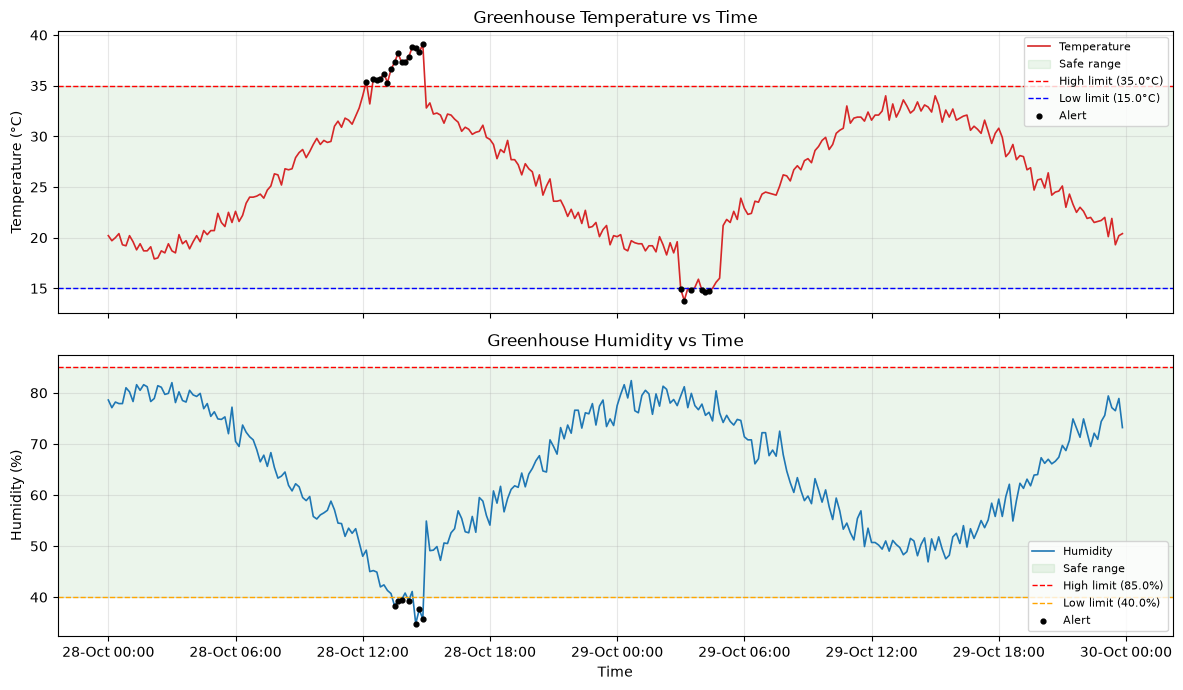

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
t = THRESHOLDS

ax1.plot(df.Time, df.Temperature_C, color="tab:red", lw=1.2, label="Temperature")
ax1.axhspan(t["TEMP_LOW"], t["TEMP_HIGH"], color="green", alpha=0.08, label="Safe range")
ax1.axhline(t["TEMP_HIGH"], color="red", ls="--", lw=1, label=f"High limit ({t['TEMP_HIGH']}°C)")
ax1.axhline(t["TEMP_LOW"], color="blue", ls="--", lw=1, label=f"Low limit ({t['TEMP_LOW']}°C)")
bad_t = df[(df.Temperature_C > t["TEMP_HIGH"]) | (df.Temperature_C < t["TEMP_LOW"])]
ax1.scatter(bad_t.Time, bad_t.Temperature_C, color="black", s=12, zorder=3, label="Alert")
ax1.set_ylabel("Temperature (°C)")
ax1.set_title("Greenhouse Temperature vs Time")
ax1.legend(loc="upper right", fontsize=8)
ax1.grid(alpha=0.3)

ax2.plot(df.Time, df.Humidity_Percent, color="tab:blue", lw=1.2, label="Humidity")
ax2.axhspan(t["HUM_LOW"], t["HUM_HIGH"], color="green", alpha=0.08, label="Safe range")
ax2.axhline(t["HUM_HIGH"], color="red", ls="--", lw=1, label=f"High limit ({t['HUM_HIGH']}%)")
ax2.axhline(t["HUM_LOW"], color="orange", ls="--", lw=1, label=f"Low limit ({t['HUM_LOW']}%)")
bad_h = df[(df.Humidity_Percent > t["HUM_HIGH"]) | (df.Humidity_Percent < t["HUM_LOW"])]
ax2.scatter(bad_h.Time, bad_h.Humidity_Percent, color="black", s=12, zorder=3, label="Alert")
ax2.set_ylabel("Humidity (%)")
ax2.set_xlabel("Time")
ax2.set_title("Greenhouse Humidity vs Time")
ax2.legend(loc="lower right", fontsize=8)
ax2.grid(alpha=0.3)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b %H:%M"))

plt.tight_layout()
plt.savefig("greenhouse_readings.png", dpi=150)
plt.show()

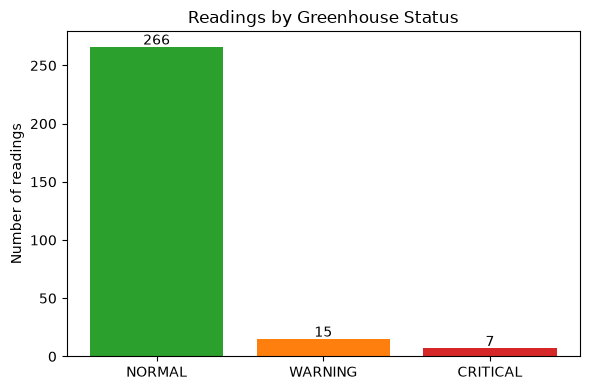

In [7]:
counts = df["Status"].value_counts().reindex(["NORMAL", "WARNING", "CRITICAL"], fill_value=0)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(counts.index, counts.values, color=["tab:green", "tab:orange", "tab:red"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 2, str(v), ha="center")
ax.set_title("Readings by Greenhouse Status")
ax.set_ylabel("Number of readings")
plt.tight_layout()
plt.savefig("greenhouse_status.png", dpi=150)
plt.show()

## Step 5 – Summary report

In [8]:
summary = pd.DataFrame({
    "Average": [df.Temperature_C.mean(), df.Humidity_Percent.mean()],
    "Minimum": [df.Temperature_C.min(), df.Humidity_Percent.min()],
    "Maximum": [df.Temperature_C.max(), df.Humidity_Percent.max()],
}, index=["Temperature (°C)", "Humidity (%)"]).round(2)
print(summary, "\n")

alert_types = {
    "High temperature": (df.Temperature_C > t["TEMP_HIGH"]).sum(),
    "Low temperature": (df.Temperature_C < t["TEMP_LOW"]).sum(),
    "Low humidity": (df.Humidity_Percent < t["HUM_LOW"]).sum(),
    "High humidity": (df.Humidity_Percent > t["HUM_HIGH"]).sum(),
}
total = len(df)
print(f"Total readings          : {total}")
print(f"Readings within limits  : {counts['NORMAL']} ({counts['NORMAL'] / total:.1%})")
print(f"Readings with alerts    : {total - counts['NORMAL']} ({(total - counts['NORMAL']) / total:.1%})")
for k, v in alert_types.items():
    print(f"  {k:22s}: {v} readings (~{v * 10} min)")

                  Average  Minimum  Maximum
Temperature (°C)    26.03     13.8     39.1
Humidity (%)        64.32     34.8     82.4 

Total readings          : 288
Readings within limits  : 266 (92.4%)
Readings with alerts    : 22 (7.6%)
  High temperature      : 16 readings (~160 min)
  Low temperature       : 6 readings (~60 min)
  Low humidity          : 7 readings (~70 min)
  High humidity         : 0 readings (~0 min)


In [9]:
# Save the data and alert log (download from the Colab file pane)
df.to_csv("greenhouse_readings.csv", index=False)
alert_rows.to_csv("greenhouse_alerts.csv", index=False)
print("Saved greenhouse_readings.csv and greenhouse_alerts.csv")

Saved greenhouse_readings.csv and greenhouse_alerts.csv


## Conclusion

* Simulated temperature and humidity readings followed a realistic day/night pattern, with two injected faults.
* Thresholds (15–35 °C, 40–85 % RH) were defined for safe crop growth.
* Every reading was checked against these limits: out-of-range readings were classed as **WARNING** (one parameter out of range) or **CRITICAL** (both out of range), logged with a timestamp, and mapped to an actuator action (exhaust fan, heater, misting, ventilation).
* The afternoon ventilation failure produced high-temperature + low-humidity CRITICAL alerts, and the cold night produced low-temperature alerts, so the logic catches both directions of failure.
* Hooked up to a real DHT22 sensor and relays (e.g. on an ESP32), this same logic becomes a working greenhouse controller.